<a href="https://colab.research.google.com/github/jocelynzhng/Facial-processing-project/blob/main/Preliminary_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data loading and inspection

In [2]:
## Load Dataset FER2013 from Kaggle

# Install KaggleHub
!pip -q install kagglehub
# Retrieve the dataset

import kagglehub
from pathlib import Path

# Download FER2013 directly into the Colab environment
dataset_path = kagglehub.dataset_download("deadskull7/fer2013")

print("Dataset location:", dataset_path)
print("Files:", list(Path(dataset_path).rglob("*")))

Using Colab cache for faster access to the 'fer2013' dataset.
Dataset location: /kaggle/input/fer2013
Files: [PosixPath('/kaggle/input/fer2013/fer2013.csv')]


In [3]:
## Load dataset into Python

import pandas as pd

# Find the FER2013 CSV file
csv_path = next(Path(dataset_path).rglob("fer2013.csv"))

# Load into a DataFrame
df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print(df["Usage"].value_counts())

df.head()
# Emotion uses numerical labels (0-6), representing correspondingly, Angry,
# Disgust, Fear, Happy, Sad, Surprise, and Neutral

Dataset shape: (35887, 3)
Usage
Training       28709
PublicTest      3589
PrivateTest     3589
Name: count, dtype: int64


,emotion,pixels,Usage
0,0,70 80 82 72 58 58 60 63 54 58 60 48 89 115 121...,Training
1,0,151 150 147 155 148 133 111 140 170 174 182 15...,Training
2,2,231 212 156 164 174 138 161 173 182 200 106 38...,Training
3,4,24 32 36 30 32 23 19 20 30 41 21 22 32 34 21 1...,Training
4,6,4 0 0 0 0 0 0 0 0 0 0 0 3 15 23 28 48 50 58 84...,Training


Dataset has 35,887 rows and 3 columns (emotion, pixels, usage).

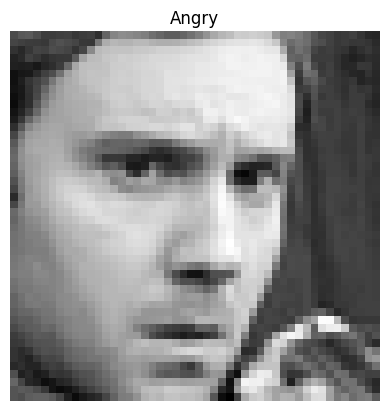

In [4]:
## Display a facial image

import numpy as np
import matplotlib.pyplot as plt

emotion_labels = [
    "Angry", "Disgust", "Fear",
    "Happy", "Sad", "Surprise", "Neutral"
]

sample = df.iloc[0]

image = np.fromstring(sample["pixels"], sep=" ")
image = image.reshape(48, 48)

plt.imshow(image, cmap="gray")
plt.title(emotion_labels[int(sample["emotion"])])
plt.axis("off")
plt.show()


## Dataset inspection
### 1. Check for class distribution

,Emotion,Count,Percentage
0,Angry,4953,13.80
1,Disgust,547,1.52
2,Fear,5121,14.27
3,Happy,8989,25.05
4,Sad,6077,16.93
5,Surprise,4002,11.15
6,Neutral,6198,17.27


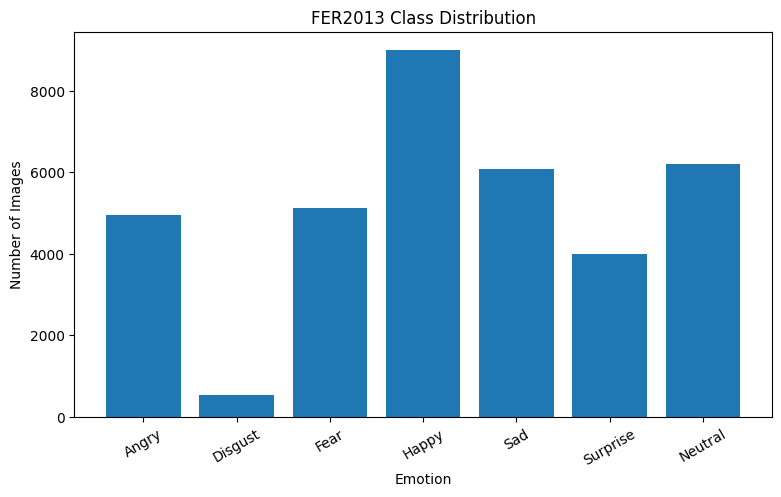

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Count images in each emotion category
class_counts = df["emotion"].value_counts().sort_index()

# Create summary table
distribution = pd.DataFrame({
    "Emotion": [emotion_labels[i] for i in class_counts.index],
    "Count": class_counts.values,
    "Percentage": (class_counts.values / len(df) * 100).round(2)
})

display(distribution)

# Plot class distribution
plt.figure(figsize=(9, 5))
plt.bar(distribution["Emotion"], distribution["Count"])
plt.xlabel("Emotion")
plt.ylabel("Number of Images")
plt.title("FER2013 Class Distribution")
plt.xticks(rotation=30)
plt.show()


FER2013 has a noticeable class imbalance:
*   Happy is overrepresented: Approximately 9,000 images, making it the largest class.
*   Disgust is severely underrepresented: Only around 550 images, roughly 16 times fewer than Happy.
*   Other emotions are relatively balanced.

### **Implications**

*   ***Model bias:*** The model may learn to recognize Happy more accurately than Disgust because it has more training examples.
*   ***Possible misleading accuracy:*** Overall accuracy may look good even if the model performs poorly on minority classes.
*   ***Takeaway for evaluation***: examine per-class recall, macro F1-score, and the confusion matrix, not just overall accuracy.
*   ***Takeaway for training:*** You may eventually consider class weighting or data augmentation to address the imbalance.



I also compare class distribution across splits
by counting images per emotion in each split.

Usage,PrivateTest,PublicTest,Training
emotion,,,
Angry,491,467,3995
Disgust,55,56,436
Fear,528,496,4097
Happy,879,895,7215
Neutral,626,607,4965
Sad,594,653,4830
Surprise,416,415,3171


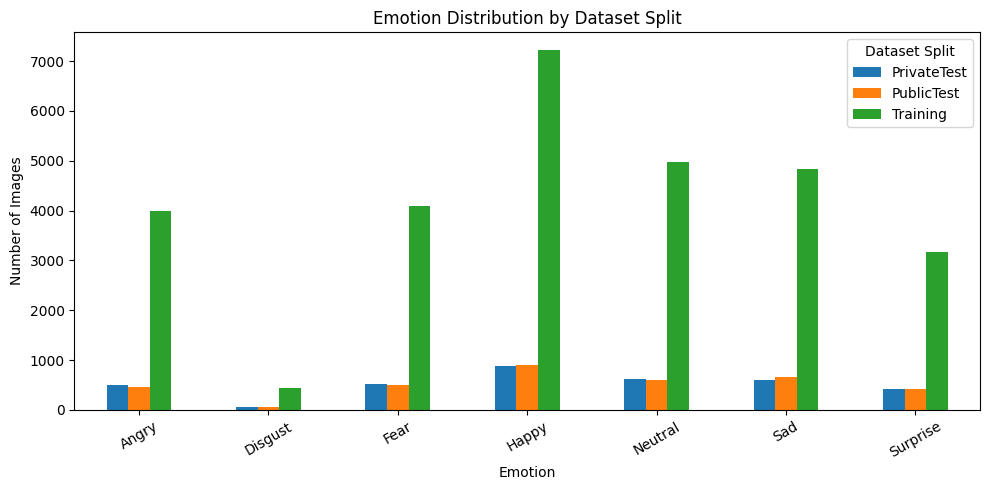

In [6]:

split_distribution = pd.crosstab(
    df["emotion"].map(dict(enumerate(emotion_labels))),
    df["Usage"]
)

display(split_distribution)

# Visualize
split_distribution.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Emotion Distribution by Dataset Split")
plt.xlabel("Emotion")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()


The class imbalance is consistent across all three splits.

## 2. Label quality
Possible concerns:


*   ***Label ambiguity:*** similar or same face expression may be reasonbaly interpreted differently by different annotators.
*   ***Incorrect labels:*** Some images may be mislabeled, particularly when facial details are difficult to distinguish.

I randomly sample 6 images across all 7 categories for visual inspection.


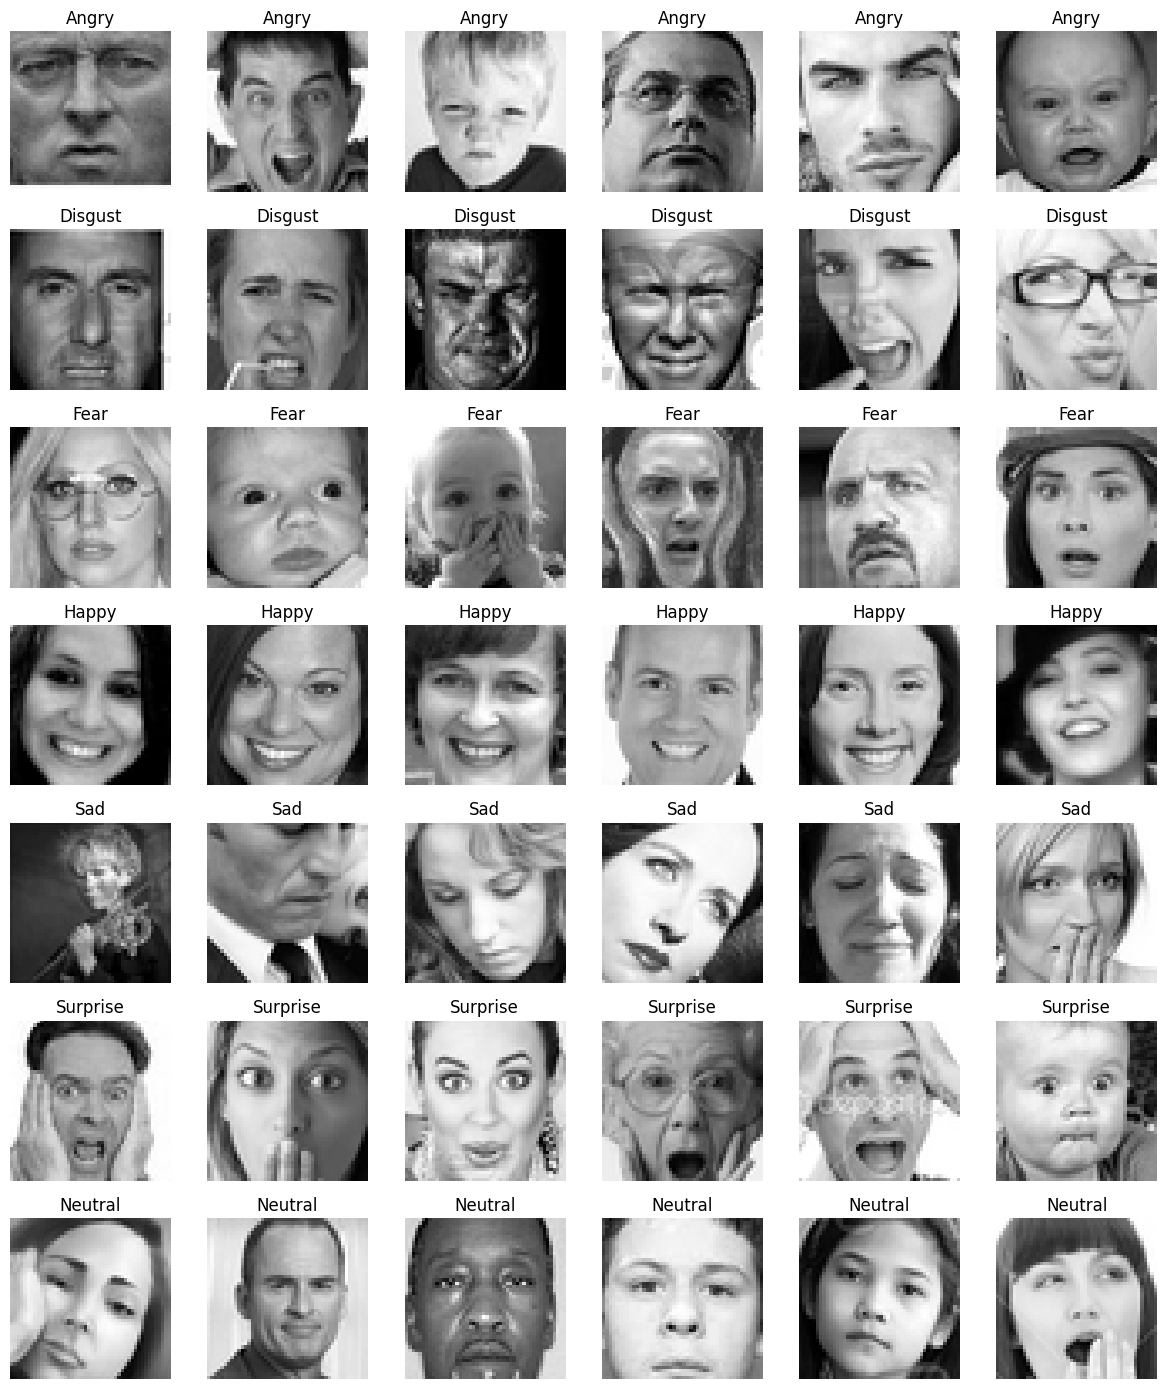

In [7]:
import numpy as np
import matplotlib.pyplot as plt

emotion_labels = ["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"]

fig, axes = plt.subplots(7, 6, figsize=(12, 14))

for emotion in range(7):
    # Randomly select 6 images from this emotion
    samples = df[df["emotion"] == emotion].sample(n=6, random_state=42)

    for j, (_, row) in enumerate(samples.iterrows()):
        # Convert pixel values into a 48x48 image
        image = np.array(row["pixels"].split(), dtype=np.uint8).reshape(48, 48)

        # Display image
        axes[emotion, j].imshow(image, cmap="gray")
        axes[emotion, j].set_title(emotion_labels[emotion])
        axes[emotion, j].axis("off")

plt.tight_layout()
plt.show()

I personally find that, in this sample, some labels are ambiguous, and can reasonably be categorized into a few expressions.

## 3. Subject identities

FER2013 does not provide subject identity labels. This means I cannot easily verify whether the same individual appears across the training, validation, and test sets.

\
This is a potential form of subject-level data leakage, which can make test performance appear better than the model's ability to generalize to completely new people.

\
However, note that the absence of identity labels does not prove that FER2013 has subject leakage. It means we cannot establish subject independence from its metadata alone.

# Preprocessing
Goal: Convert the raw FER2013 dataset into a format that a CNN can use for training and evaluation.

\
First, I convert pixel strings into arrays, so that raw pixel data is translated into image matrices that preserves the spatial arrangement of pixels, which is then usable by a CNN and allows it to detect patterns.

In [8]:
import numpy as np

# Convert pixel strings into 48x48 image arrays
X = np.stack([
    np.fromstring(pixels, sep=" ", dtype=np.uint8).reshape(48, 48)
    for pixels in df["pixels"]
])

# Extract emotion labels
y = df["emotion"].to_numpy()

print("Image shape:", X.shape)
print("Label shape:", y.shape)

Image shape: (35887, 48, 48)
Label shape: (35887,)


I then normalize pixel values which generally makes neural-network training more stable.

In [9]:
# Normalize pixel values
X = X.astype("float32") / 255.0

# Add channel dimension for CNN input
X = X[..., np.newaxis]

print("Normalized image shape:", X.shape)
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())

Normalized image shape: (35887, 48, 48, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


Note that the The additional "1" represents the single grayscale color channel.


Next, I create training, validation, and test sets according to FER2013's predefined splits through the Usage column.

In [10]:
# Identify each split
train_mask = df["Usage"] == "Training"
val_mask = df["Usage"] == "PublicTest"
test_mask = df["Usage"] == "PrivateTest"

# Split images and labels
X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

# Verify dimensions
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (28709, 48, 48, 1) (28709,)
Validation: (3589, 48, 48, 1) (3589,)
Test: (3589, 48, 48, 1) (3589,)


# Baseline classifier
Now I train a simple CNN to for facial expression classification and evaluate its performance. This establish a baseline for DINOv2.

\
To start, we set up TensorFlow and Keras.

In [11]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models

# Set random seeds for reproducibility
tf.keras.utils.set_random_seed(42)

# Check TensorFlow version and GPU availability
print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Define a simple CNN architecture

Next, I define a simple CNN architecture, with three convolutional blocks, followed by dense layers, which combine learned features for classification, before emotion probabibilities (Softmax classification) are produced as output.


**Key components:**
- Conv2D: Learns visual features from images.
- MaxPooling2D: Reduces image dimensions while retaining important features.
- Dense: Combines extracted features to classify emotions.
- Dropout(0.5): Helps reduce overfitting during training.
- Softmax: Produces probabilities for all seven emotion categories.

In [12]:
model = models.Sequential([
    layers.Input(shape=(48, 48, 1)),

    # Convolutional block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(7, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,527 (2.61 MB)

 Trainable params: 683,527 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

###Output legend

| Column | Meaning |
|---|---|
| **Layer (type)** | What operation the model performs |
| **Output Shape** | The dimensions of the data after that layer |
| **Param #** | Number of parameters (weights and biases) associated with that layer |



**CNN Architecture explained with an example:**

\
Our input, the original grayscale image, is 48 × 48 × 1.

Through Conv2D, the dimension becomes 48 × 48 × 32, where 32 feature maps are learned, detecting patterns such as edges.

Through MaxPooling, the dimension becomes 24 × 24 × 32, i.e., spatial dimensions is reduced by half.

Then Con2D extracs 64 inceasingly complex feature maps, and the dimension becomes 24 × 24 × 64.  

MaxPooling again reduces the spatial dimensions by half to 12 × 12 × 64.

This process is repeated another time, where the shape then becomes 12 × 12 × 128, then 6 × 6 × 128, and eventually flattened into a single vector of 4608 values.



## Compile the CNN

In [13]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## Train the CNN

We'll train using the training set and monitor performance using the validation set.

For the initial experiment, use:
- Epochs: Maximum 20 (one epoch = one complete pass through the training data).
- Batch size: 64 images per weight update.
- Early stopping: Stop if validation loss fails to improve for five consecutive epochs.

In [14]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 27s 35ms/step - accuracy: 0.3015 - loss: 1.7361 - val_accuracy: 0.4149 - val_loss: 1.5280
Epoch 2/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.4198 - loss: 1.5097 - val_accuracy: 0.4756 - val_loss: 1.3774
Epoch 3/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.4709 - loss: 1.3930 - val_accuracy: 0.4990 - val_loss: 1.3017
Epoch 4/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.5003 - loss: 1.3167 - val_accuracy: 0.5185 - val_loss: 1.2625
Epoch 5/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.5279 - loss: 1.2556 - val_accuracy: 0.5297 - val_loss: 1.2419
Epoch 6/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.5481 - loss: 1.1988 - val_accuracy: 0.5350 - val_loss: 1.2253
Epoch 7/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.5626 - loss: 1.1487 - val_accuracy: 0.5352 - val_loss: 1.2232
Epoch 8/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.5790 - loss: 1.1074 - val_accuracy:

Training and validation accuracy both increase as the model learns, a good sign that the model is not overfitting.

# Evaluate model performance
Now I evaluate the trained CNN over a few metrics.

### 1. Overall test accuracy
This measures the final model's performance on the held-out test set.

In [15]:
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test loss: {test_loss:.4f}")

Test accuracy: 0.5561
Test loss: 1.1755


### 2. Per-class performance and macro F1-score

Examine whether the CNN performs differently across emotion categories.

In [16]:
from sklearn.metrics import classification_report, f1_score

emotion_labels = [
    "Angry", "Disgust", "Fear", "Happy",
    "Sad", "Surprise", "Neutral"
]

# Predict probabilities
y_pred_prob = model.predict(X_test)

# Convert probabilities to predicted class labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Classification report
print(classification_report(
    y_test,
    y_pred,
    labels=range(7),
    target_names=emotion_labels,
    zero_division=0
))

# Macro F1-score
macro_f1 = f1_score(y_test, y_pred, average="macro")

print(f"Macro F1-score: {macro_f1:.4f}")

113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
              precision    recall  f1-score   support

       Angry       0.42      0.51      0.46       491
     Disgust       0.50      0.04      0.07        55
        Fear       0.39      0.27      0.32       528
       Happy       0.71      0.84      0.77       879
         Sad       0.45      0.32      0.37       594
    Surprise       0.66      0.72      0.69       416
     Neutral       0.53      0.60      0.56       626

    accuracy                           0.56      3589
   macro avg       0.52      0.47      0.46      3589
weighted avg       0.54      0.56      0.54      3589

Macro F1-score: 0.4626


## Visualize model performance

### A. Training and validation curves

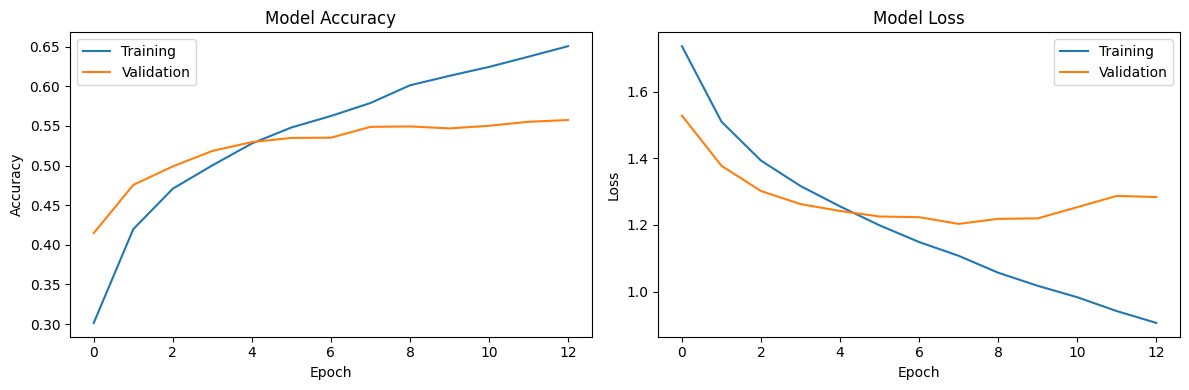

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Accuracy
axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

# Loss
axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

### Confusion matrix
I determine which emotions are most frequently confused with one another.

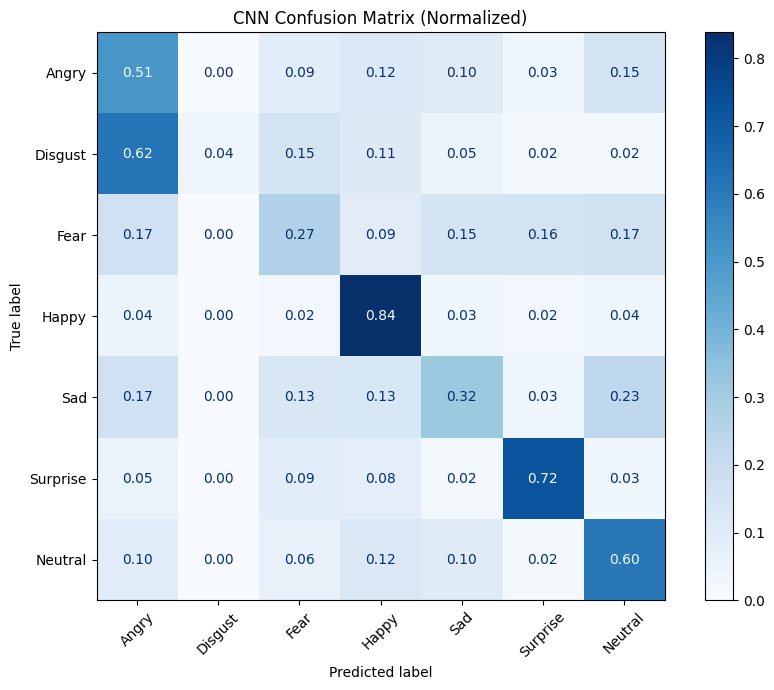

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=range(7),
    display_labels=emotion_labels,
    cmap="Blues",
    normalize="true",
    values_format=".2f",
    ax=ax
)

plt.title("CNN Confusion Matrix (Normalized)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()